# 02 · Putting the wave on a quantum computer (1D → 2D → 3D)

**Idea (Costa, Jordan & Ostrander 2019):** the sound equation can be rewritten as the same kind of equation a quantum
computer naturally runs. The quantum state's numbers become *the wave energy in each cube (and each link between cubes)*.
Measuring the qubits lands on one cube; how often it lands on a transducer's cube = how much sound reached it.

Two ways to store it:

| encoding | qubits | gates | catch |
|---|---|---|---|
| **compact** (cube number written in binary) | log₂(cubes + links) → **29 for the real head** | huge, tangled | can't run on today's chips |
| **unary** (one qubit per cube/link) | cubes + links | small, local 2-qubit gates | no memory advantage; classically easy |

This notebook proves both encodings reproduce the classical wave, in 1D, 2D **and 3D**, and measures what they cost.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # so `import qwave` works from notebooks/
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RESULTS = pathlib.Path.cwd().parent / "results"; RESULTS.mkdir(exist_ok=True)
from qwave import Grid, head_phantom
from qwave.classical import exact_receiver_energy
from qwave.encoding import compact_qubits, unary_qubits, compact_pauli_op
from qwave.circuits import (compact_circuit, compact_receiver_probs, unary_circuit, unary_receiver_probs,
                            gate_cost, compact_cz_estimate)

def problem(shape):
    g = Grid(shape); c, _ = head_phantom(shape); c = c.ravel()
    src = g.index(*([0] + [s // 2 for s in shape[1:]]))
    rx = [g.index(*([shape[0] - 1] + [s // 2 for s in shape[1:]])), g.index(*[s // 2 for s in shape])]
    return g, c, src, rx

## Qubit counts

In [2]:
for shape in [(7,), (3, 3), (3, 3, 3), (7, 7, 7)]:
    g = Grid(shape)
    print(f"{str(shape):>10}: cubes={g.n_vertices:4d} links={g.n_edges:5d} | compact qubits={compact_qubits(g):2d} | unary qubits={unary_qubits(g)}")

      (7,): cubes=   7 links=    8 | compact qubits= 4 | unary qubits=15
    (3, 3): cubes=   9 links=   24 | compact qubits= 6 | unary qubits=33
 (3, 3, 3): cubes=  27 links=  108 | compact qubits= 8 | unary qubits=135
 (7, 7, 7): cubes= 343 links= 1176 | compact qubits=11 | unary qubits=1519


## Does the quantum circuit match the classical wave? (noiseless simulator, real gate-by-gate circuits)

In [3]:
rows = []
T = 1.5
for shape in [(7,), (3, 3), (3, 3, 3)]:
    g, c, src, rx = problem(shape)
    ex = exact_receiver_energy(g, c, [T], src, rx)[0]
    for steps in (2, 4, 8):
        qc = unary_circuit(g, c, T, steps, src)
        err = np.abs(unary_receiver_probs(qc, rx) - ex).max()
        rows.append((shape, "unary", steps, qc.num_qubits, gate_cost(qc)["cz"], err))
        if len(shape) < 3:                          # compact circuits are too big to even compile in 3D
            qc = compact_circuit(g, c, T, steps, src)
            err = np.abs(compact_receiver_probs(qc, rx) - ex).max()
            rows.append((shape, "compact", steps, qc.num_qubits, gate_cost(qc)["cz"], err))
        else:
            op = compact_pauli_op(g, c)
            rows.append((shape, "compact (estimate)", steps, op.num_qubits, compact_cz_estimate(op, steps), float("nan")))
print(f"{'grid':>10} {'encoding':>19} {'steps':>5} {'qubits':>6} {'CZ gates':>10} {'max error vs classical':>24}")
for r in rows:
    print(f"{str(r[0]):>10} {r[1]:>19} {r[2]:5d} {r[3]:6d} {r[4]:10d} {r[5]:24.5f}")

      grid            encoding steps qubits   CZ gates   max error vs classical
      (7,)               unary     2     15         70                  0.00136
      (7,)             compact     2      4        336                  0.00287
      (7,)               unary     4     15        126                  0.00063
      (7,)             compact     4      4        694                  0.00049
      (7,)               unary     8     15        238                  0.00017
      (7,)             compact     8      4       1414                  0.00011
    (3, 3)               unary     2     33        234                  0.02518
    (3, 3)             compact     2      6       8602                  0.01000
    (3, 3)               unary     4     33        450                  0.01475
    (3, 3)             compact     4      6      17916                  0.00126
    (3, 3)               unary     8     33        882                  0.00378
    (3, 3)             compact     8    

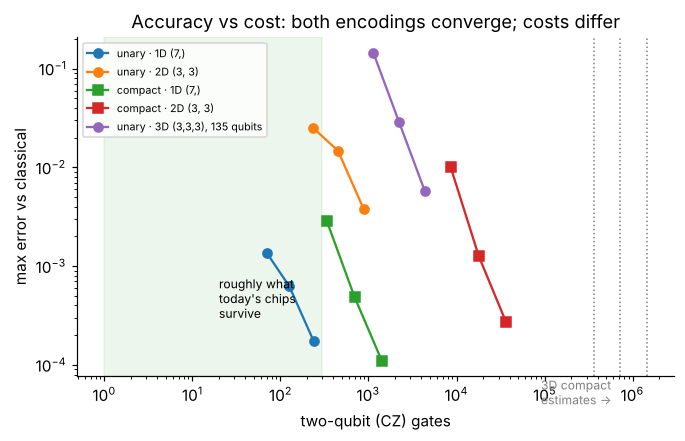

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for enc, mk in (("unary", "o-"), ("compact", "s-")):
    for shape in [(7,), (3, 3)]:
        pts = [(r[4], r[5]) for r in rows if r[0] == shape and r[1] == enc]
        ax.loglog(*zip(*pts), mk, label=f"{enc} · {len(shape)}D {shape}")
pts3 = [(r[4], r[5]) for r in rows if r[0] == (3, 3, 3) and r[1] == "unary"]
ax.loglog(*zip(*pts3), "o-", label="unary · 3D (3,3,3), 135 qubits")
est = [r[4] for r in rows if r[1].startswith("compact (")]
for x in est: ax.axvline(x, color="gray", ls=":", lw=1)
ax.axvspan(1, 300, color="green", alpha=0.07); ax.text(20, 3e-4, "roughly what\ntoday's chips\nsurvive", fontsize=8)
ax.text(est[0] * 0.25, 4e-5, "3D compact\nestimates →", fontsize=8, color="gray")
ax.set(xlabel="two-qubit (CZ) gates", ylabel="max error vs classical", title="Accuracy vs cost: both encodings converge; costs differ")
ax.legend(fontsize=7); plt.savefig(RESULTS / "02_cost_accuracy.png", bbox_inches="tight"); plt.show()

**Takeaways**
1. Both encodings reproduce the classical wave in 1D and 2D; the unary circuit also does in **3D** (135 qubits, error < 0.01).
2. The compact encoding (the one with the big memory advantage) costs **~40× more gates** in 2D, and in 3D even a 3×3×3
   head needs ~10⁶ gates — far beyond any current chip. The tangled gates come from writing a grid in binary.
3. The unary encoding is cheap per step but uses one qubit per cube, so it gives up the advantage.
   *The encoding that would help can't run; the one that runs doesn't help.* — the core of our quantum rationale.